# **>>> Summary**
The purpose of this program/notebook, is to create a pipeline for testing how integrating domain terms (terms associated with a certain domain) into passwords affects their security. We re-create the methodology introduced by the academic paper ["The Effect of Domain Terms on Password Security"](https://dl.acm.org/doi/10.1145/3703350).


Our implementation has 4 key stages:
1.   Extract domain terms from Wikipedia article text using the TextRank algorithm. The chosen domains are **Finance, IT, and Medicine.**
2.   Use the "Fixed-Category Substitution" algorithm to integrate the domain terms into a dataset of passwords, creating a new set of domain-specific passwords. The dataset used can be found [here](https://github.com/danielmiessler/SecLists/blob/master/Passwords/Leaked-Databases/phpbb.txt).
3.   Use PCFG (Probabilistic Context-Free Grammar) to create a model for generating new passwords, based on a trainig set of domain-specific passwords.
4.   Run a password cracking attack simulation, using the PCFG model and a testing set of passwords.



#**>>> How To Run The Code**
To run the code:
*   Download the PHPBB password dataset [here](https://github.com/danielmiessler/SecLists/blob/master/Passwords/Leaked-Databases/phpbb.txt) as a text file.
*   Rename it to "phpbb_passwords.txt", and upload it to the Google Colab environment. If running this notebook locally, then move the file into the same directory as the notebook.
*   Click "Run All" at the top of the page.

The code is divided into:
*   "Library Imports" - Imports or downloads the necessary libraries.
*   "Functions Area" - Defines the functions that make up each part of the pipeline.
*   "Code Execution Area" - Runs the pipeline (the 4 implemnetation stages described above).

To learn more about how the underlying code works, read the function descriptions within the Functions Area (ideally in order).  
To see the results of the attack simulation once it has finished, scroll down to the final two cells of the notebook.


## **>>> Library Imports**

In [ ]:
!pip install pytextrank
!python -m spacy download en_core_web_sm
!pip install matplotlib
!pip install numpy
!pip install requests

In [ ]:
import requests, json
import time
import re
import random

import spacy
import pytextrank

import matplotlib.pyplot as plt
import numpy as np

# **>>> Functions Area**

#### **>>> Extracting the plaintext of Wikipedia articles**

In [ ]:
def extract_article_content (article_title : str, edition_code : str = 'en'):
    """
    This function retrieves the plaintext content of a Wikipedia article, using MediaWiki's TextExtracts API.

    :article_title: The title of the target Wikipedia article.
    :edition_code: The code for the target Wikipedia language edition. The default is 'en' for the English Wikipedia edition.

    Returns the article content as a string, or None if the request to the API was unsuccessful.
    """
    url = "https://" + edition_code + ".wikipedia.org/w/api.php?action=query&prop=extracts&titles=" + article_title + "&explaintext=1&format=json"

    headers = {"User-Agent" : "Wikipedia Article Content Extraction"}
    # If the user agent is not set, or it is overly generic, then the response will be a 403 error.

    response = requests.get(url, headers=headers)

    if response.status_code == 200:
        data = response.json()
        content = data['query']['pages']
        content = content[list(content.keys())[0]]['extract']
        print(f"The content of the article '{article_title}' ({edition_code}) was successfully retrieved.")
        return content
    else:
        print(f"The content of the article '{article_title}' ({edition_code}) could not be retrieved (error status code: {response.status_code}).")
        return None


def pre_process_article_content(content : str):
    """
    This function simply removes the headers at the end of most Wikipedia articles.
    This is to ensure that they are not counted as domain terms.
    """
    new_content = content.split("== References ==", 1)[0].split("== Notes ==", 1)[0].split("== See also ==", 1)[0]
    return new_content


#### **>>> Using PyTextRank**

In [ ]:
# Load the core English SpaCy model
textrank_model = spacy.load("en_core_web_sm")

# Add PyTextRank to the spaCy pipeline
# This allows the TextRank algorithm to be called as a function
textrank_model.add_pipe("textrank")

#### **>>> Implementing the Fixed-Category Substitution Algorithm**

In [ ]:
def identify_sequences(password_list : list):
    """
    This function takes a list of passwords and counts the number of letter sequences across all of the passwords.
    A letter sequence is a continuous substring of letters within a string. As an example, "2hard4me" contains the letter sequences 'hard' and 'me'.

    :password_list: A list of strings containing the passwords.

    Returns a dictionary containing the frequency of each letter sequence, sorted in descending order of frequency.
    """
    sequence_frequency = dict()

    for password in password_list:
        sequences = re.findall(r'[a-zA-Z]+', password)
        for s in sequences:
            if s in sequence_frequency:
                sequence_frequency[s] += 1
            else:
                sequence_frequency [s] = 1

    sequence_frequency = {k: v for k, v in sorted(sequence_frequency.items(), key=lambda item: item[1], reverse=True)}
    return sequence_frequency

In [ ]:
def substitute_domain_terms(password_list : list, sequence_dict : dict, domain_terms : list, sub_ratio : float = 0.2):
    """
    This function integrates a set of domain terms into a list of passwords.

    :password_list: The list of passwords (as strings) to integrate the domain terms into.
    :sequence_list: A dictionary containing the frequency of each letter sequence in password_list.
    :domain_terms: A list of domain terms. domain_terms[x] will replace every occurrence of sequence_list[x] across password_list.
    :sub_ratio: Determines what proportion of the (most frequently appearing) string sequences will be replaced with domain terms.
    The default is 0.2, meaning 20% of the sequences will be replaced with domain terms, if there are enough of the latter.

    Returns the domain-specific passwords (with the domain terms integrated) as a list of strings.
    """
    no_of_subs = min(len(domain_terms), round(len(sequence_dict) * sub_ratio))

    sub_dict = {list(sequence_dict)[x] : domain_terms[x] for x in range(no_of_subs)}

    domain_passwords = []

    for password in password_list:
        d_password = re.sub( r'[a-zA-Z]+', lambda match: sub_dict.get(match.group(), match.group()), password)
        domain_passwords.append(d_password)

    return domain_passwords

#### **>>> Splitting Passwords Into Training and Testing Sets**

In [ ]:
def train_test_split_passwords(password_list : list, train_test_ratio : tuple = (4,1)):
    """
    This function takes a list of passwords (as strings) and splits them between a training set and a testing set.

    :train_test_ratio: A tuple in the format (x, y), meaning for every x passwords in the training set, there will be y in the testing set.

    Returns the training and testing sets as two lists of passwords.
    Note that, given the same password list and ratio, this function will return the same train-test sets each time.
    """
    if train_test_ratio[0] < 1 or train_test_ratio[1] < 1:
        train_test_ratio = (4,1)

    train_set = []
    test_set = []
    assign_to_train = True
    count = 0

    for password in password_list:
        if assign_to_train == True:
            train_set.append(password)
            count += 1
            if count >= train_test_ratio[0]:
                assign_to_train = False
                count = 0
        else:
            test_set.append(password)
            count += 1
            if count >= train_test_ratio[1]:
                assign_to_train = True
                count = 0

    return train_set, test_set

#### **>>> Training the PCFG (Probabilistic Context-Free Grammar) Model**

In [ ]:
def train_pcfg_model (training_passwords : list):
    """
    This function trains a PCFG model based on the inputted list of passwords.
    For each password, its structure (the sequences of letters, digits, and symbols it is composed of) is determined.
    For example, the structure of "12abc34" is 2 digits, 3 letters, 2 digits (or 2D3L2D for short).
    A dictionary is used to track how frequently each structure occurs, and another is used to track the frequency of each sequence.
    At the end, both dictionaries are converted to use cumulative frequency.

    :training_passwords: The list of passwords that this model will be based on.

    Returns the PCFG model, which takes the form of a structure frequency dictionary, and a sequence frequency dictionary
    """
    structure_dict = dict()
    sequence_dict = dict()

    for password in training_passwords:
        char_type = ""
        sequence = ""
        strseq = ""
        structure = []

        for i in range(len(password)):
            # This loop iterates through each character of the current password, to identify its composite sequences
            # It keeps track of the previous character's type, so it can determine in a sequence has ended.
            c = password[i]

            if char_type == "":
                if c.isalpha():
                    char_type = 'L'
                elif c.isdigit():
                    char_type = 'D'
                else:
                    char_type = 'S'
                sequence += c

            elif c.isalpha():
                if char_type == 'L':
                    sequence += c
                else:
                    strseq = str(len(sequence)) + char_type
                    structure.append(strseq)
                    if strseq in sequence_dict:
                        if sequence in sequence_dict[strseq]:
                            sequence_dict[strseq][sequence] += 1
                        else:
                            sequence_dict[strseq][sequence] = 1
                    else:
                        sequence_dict[strseq] = {sequence : 1}
                    char_type = 'L'
                    sequence = c

            elif c.isdigit():
                if char_type == 'D':
                    sequence += c
                else:
                    strseq = str(len(sequence)) + char_type
                    structure.append(strseq)
                    if strseq in sequence_dict:
                        if sequence in sequence_dict[strseq]:
                            sequence_dict[strseq][sequence] += 1
                        else:
                            sequence_dict[strseq][sequence] = 1
                    else:
                        sequence_dict[strseq] = {sequence : 1}
                    char_type = 'D'
                    sequence = c

            else:
                if char_type == 'S':
                    sequence += c
                else:
                    strseq = str(len(sequence)) + char_type
                    structure.append(strseq)
                    if strseq in sequence_dict:
                        if sequence in sequence_dict[strseq]:
                            sequence_dict[strseq][sequence] += 1
                        else:
                            sequence_dict[strseq][sequence] = 1
                    else:
                        sequence_dict[strseq] = {sequence : 1}
                    char_type = 'S'
                    sequence = c

            if i == len(password) - 1:
                strseq = str(len(sequence)) + char_type
                structure.append(strseq)
                if strseq in sequence_dict:
                    if sequence in sequence_dict[strseq]:
                        sequence_dict[strseq][sequence] += 1
                    else:
                        sequence_dict[strseq][sequence] = 1
                else:
                    sequence_dict[strseq] = {sequence : 1}

        structure = tuple(structure)
        if structure in structure_dict:
            structure_dict[structure] += 1
        else:
            structure_dict[structure] = 1

    # Convert each dictionary to use cumulative frequency.
    cumulative = 0
    for k, v in structure_dict.items():
        structure_dict[k] = cumulative + v
        cumulative += v

    for seq in sequence_dict:
        cumulative = 0
        for k, v in sequence_dict[seq].items():
            sequence_dict[seq][k] = cumulative + v
            cumulative += v

    return (structure_dict, sequence_dict)

#### **>>> Generating Passwords with the PCFG Model**

In [ ]:
def generate_pcfg_password (pcfg_model : tuple):
    """
    This function generates a password using the given PCFG model.
    The cumulative frequencies stored by the model correspond to the probability of a given passowrd structure or sequence being chosen.
    First, a password structure is selected based on the model frequencies/probabilities.
    Next, sequences are selected based on the chosen structure, and then the model frequencies/probabilities.
    For example, if the chosen structure is "4 letters, 2 symbols", the randomly chosen sequences might be "Work" and "??".
    Finally, the sequences are combined in order, to produce the generated password.

    :pcfg_model: The PCFG model that should be used to generate the password. This should be the output of train_pcfg_model().
    """
    structure_count = max(pcfg_model[0].values())
    rand_num = random.randint(1, structure_count)
    generated_password = ""

    for structure in list(pcfg_model[0].keys()):
        if rand_num <= pcfg_model[0][structure]:
            for strseq in structure:
                sequence_count = max(pcfg_model[1][strseq].values())
                rand_num = random.randint(1, sequence_count)

                for sequence in list(pcfg_model[1][strseq].keys()):
                    if rand_num <= pcfg_model[1][strseq][sequence]:
                        generated_password += sequence
                        break
            break

    return generated_password

In [ ]:
def generate_pcfg_password_v2 (pcfg_model : tuple, structure_count : int):
    """
    This function is a more efficient re-implementation of generate_pcfg_password().
    """
    rand_num = random.randint(1, structure_count)
    generated_password = ""
    password_structure = list()

    for structure in list(pcfg_model[0].keys()):
        if rand_num <= pcfg_model[0][structure]:
            password_structure = structure
            for strseq in structure:
                sequence_count = max(pcfg_model[1][strseq].values())
                rand_num = random.randint(1, sequence_count)

                for sequence in list(pcfg_model[1][strseq].keys()):
                    if rand_num <= pcfg_model[1][strseq][sequence]:
                        generated_password += sequence
                        break
            break

    return generated_password, password_structure

#### **>>> Simulating a Password Cracking Attack on a Testing Set of Passwords**

In [ ]:
def simulate_cracking_attack (pcfg_model : tuple, testing_passwords : list, max_guesses : int = 10000):
    """
    This function simulates a password cracking attack, using the PCFG model to generate passwords.
    Each unique password generated is counted as one 'guess' (previously generated passwords are not counted).
    A password is cracked if a password in the testing set matches the generated password.

    :pcfg_model: The PCFG model that should be used to generate the password. This should be the output of train_pcfg_model().
    :testing_passwords: The list of passwords that should be used for the cracking attack.
    :max_guesses: The maximum number of guesses that will be performed in this attack.

    Returns the list of cracked passwords, and a list of tuples in the format [(number of guesses, number of cracked passwords)]
    """
    password_count = len(testing_passwords)
    guessed_passwords = dict()
    cracked_passwords = []
    cracking_rate = []
    structure_count = max(pcfg_model[0].values())

    guesses = 0 # Only counts the number of unique guessed (generated) passwords
    # Passwords that have been previously guessed will not be counted

    while guesses < max_guesses and len(cracked_passwords) < password_count:
        password, structure = generate_pcfg_password_v2(pcfg_model, structure_count)

        if structure not in guessed_passwords:
            guessed_passwords[structure] = []

        if password not in guessed_passwords[structure]:
            guesses += 1
            guessed_passwords[structure].append(password)

            if password in testing_passwords:
                cracked_passwords.append(password)

            if guesses % 100 == 0 and guesses != max_guesses:
                cracking_rate.append((guesses, round(len(cracked_passwords) / password_count, 6)))

    cracking_rate.append((guesses, round(len(cracked_passwords) / password_count, 6)))

    return cracked_passwords, cracking_rate

#### **>>> Graphing the Password Cracking Rate**

In [ ]:
def graph_cracking_rate (crack_rate : list, graph_title : str):
    """
    This function creates a graph of the password cracking rate against the number of guesses, using Matplotlib.
    This is for attack simulations run using the simulate_cracking_attack() function.

    :crack_rate: A list of tuples in the format [(number of guesses, number of cracked passwords)].
    :graph_title: The title of the graph to be produced
    """
    x_guesses = np.array([x[0] for x in crack_rate])
    y_cracks = np.array([y[1] * 100 for y in crack_rate])

    plt.figure(figsize=(5, 5), dpi=200)
    plt.plot(x_guesses, y_cracks, linewidth=5)
    plt.title(graph_title, fontdict = {'family' : 'serif', 'size' : 12})
    plt.xlabel("Number of Guesses", fontdict = {'family' : 'serif', 'size' : 10})
    plt.ylabel("% of Passwords Cracked", fontdict = {'family' : 'serif', 'size' : 10})
    plt.grid()
    plt.show()

# **>>> Code Execution Area**

### Extracting the text of Wikipedia articles on the three domains (Medicine, IT, Finance).

In [ ]:
medicine_wikipedia_titles = ["Medicine", "Disease", "Medical_doctor", "Health_care", "Medication", "Patient", "Health_professional", "Infection", "Science", "Hospital"]
it_wikipedia_titles = ["Information_technology", "Computer", "Computer_science", "Computer_engineering", "Computer_hardware", "Software", "Information_Age", "Computer_network", "Computer_programming", "Software_development"]
finance_wikipedia_titles = ["Finance", "Money", "Financial_system", "Bank", "Investment", "Economics", "Stock", "Financial_market", "Loan", "Debt"]

medicine_wiki_content = ""
it_wiki_content = ""
finance_wiki_content = ""

for title in medicine_wikipedia_titles:
    temp_content = None
    while temp_content == None:
        temp_content = extract_article_content(title)
        time.sleep(2)
    medicine_wiki_content += pre_process_article_content( temp_content )

for title in it_wikipedia_titles:
    temp_content = None
    while temp_content == None:
        temp_content = extract_article_content(title)
        time.sleep(2)
    it_wiki_content += pre_process_article_content( temp_content )

for title in finance_wikipedia_titles:
    temp_content = None
    while temp_content == None:
        temp_content = extract_article_content(title)
        time.sleep(2)
    finance_wiki_content += pre_process_article_content( temp_content )

### Using the TextRank algorithm to generate and rank domain terms from the extracted Wikipedia text.

In [ ]:
medicine_doc = textrank_model( medicine_wiki_content )
it_doc = textrank_model( it_wiki_content )
finance_doc = textrank_model( finance_wiki_content )

medicine_domain_terms = []
it_domain_terms = []
finance_domain_terms = []

count = 0
# print("Medicine Domain Terms: ")
for phrase in medicine_doc._.phrases:
    for chunk in phrase.chunks:
        for token in chunk:
            if not token.is_punct and not token.is_stop and token.is_alpha and token.text.lower() not in medicine_domain_terms:
                # print(token.text.lower())
                medicine_domain_terms.append(token.text.lower())
    count += 1
    if count == 1000:
        break

count = 0
# print("\nIT Domain Terms: ")
for phrase in it_doc._.phrases:
    for chunk in phrase.chunks:
        for token in chunk:
            if not token.is_punct and not token.is_stop and token.is_alpha and token.text.lower() not in it_domain_terms:
                # print(token.text.lower())
                it_domain_terms.append(token.text.lower())
    count += 1
    if count == 1000:
        break

count = 0
# print("\nFinance Domain Terms: ")
for phrase in finance_doc._.phrases:
    for chunk in phrase.chunks:
        for token in chunk:
            if not token.is_punct and not token.is_stop and token.is_alpha and token.text.lower() not in finance_domain_terms:
                # print(token.text.lower())
                finance_domain_terms.append(token.text.lower())
    count += 1
    if count == 1000:
        break

### Writing the domain terms to (separate) text files.

In [ ]:
with open("medicine_domain_terms.txt", "w") as medicine_file:
    medicine_file.writelines("\n".join(medicine_domain_terms))

with open("it_domain_terms.txt", "w") as it_file:
    it_file.writelines("\n".join(it_domain_terms))

with open("finance_domain_terms.txt", "w") as finance_file:
    finance_file.writelines("\n".join(finance_domain_terms))

### Reading the domain terms from a text file.

In [ ]:
medicine_domain_terms = []
with open("medicine_domain_terms.txt", "r") as medicine_file:
    for line in medicine_file:
        medicine_domain_terms.append(line.strip())

it_domain_terms = []
with open("it_domain_terms.txt", "r") as it_file:
    for line in it_file:
        it_domain_terms.append(line.strip())

finance_domain_terms = []
with open("finance_domain_terms.txt", "r") as finance_file:
    for line in finance_file:
        finance_domain_terms.append(line.strip())

### Reading the password dataset from a text file.

In [ ]:
original_password_dataset = []
with open("phpbb_passwords.txt", "r") as password_file:
    for line in password_file:
        original_password_dataset.append(line.strip())

### Counting the letter sequences within the passwords.

In [ ]:
password_sequences = identify_sequences(original_password_dataset)

for k, v in password_sequences.items():
    # print(k, " - ", v)
    if v == 3:
        break

### Substituting the sequences for domain terms within each password.

In [ ]:
medicine_domain_passwords = substitute_domain_terms(original_password_dataset, password_sequences, medicine_domain_terms)
it_domain_passwords = substitute_domain_terms(original_password_dataset, password_sequences, it_domain_terms)
finance_domain_passwords = substitute_domain_terms(original_password_dataset, password_sequences, finance_domain_terms)

# print([x for x in zip(original_password_dataset, it_domain_passwords)])

### Writing the domain-specific passwords to text files.

In [ ]:
with open("phpbb_medicine_passwords.txt", "w") as medicine_file:
    medicine_file.writelines("\n".join(medicine_domain_passwords))

with open("phpbb_it_passwords.txt", "w") as it_file:
    it_file.writelines("\n".join(it_domain_passwords))

with open("phpbb_finance_passwords.txt", "w") as finance_file:
    finance_file.writelines("\n".join(finance_domain_passwords))

### Reading the domain specific passwords from text files.

In [ ]:
medicine_domain_passwords = []
with open("phpbb_medicine_passwords.txt", "r") as medicine_file:
    for line in medicine_file:
        medicine_domain_passwords.append(line.strip())

it_domain_passwords = []
with open("phpbb_it_passwords.txt", "r") as it_file:
    for line in it_file:
        it_domain_passwords.append(line.strip())

finance_domain_passwords = []
with open("phpbb_finance_passwords.txt", "r") as finance_file:
    for line in finance_file:
        finance_domain_passwords.append(line.strip())

### Splitting the domain specific passwords (and the original password dataset) into training and testing sets.

In [ ]:
original_train_passwords, original_test_passwords = train_test_split_passwords(original_password_dataset)
medicine_train_passwords, medicine_test_passwords = train_test_split_passwords(medicine_domain_passwords)
it_train_passwords, it_test_passwords = train_test_split_passwords(it_domain_passwords)
finance_train_passwords, finance_test_passwords = train_test_split_passwords(finance_domain_passwords)

### Training PCFG models for each training set of passwords (original, medicine, IT, finance).

In [ ]:
# This cell demonstrates how the PCFG model parses the training set.

sample_passwords = ["pass", "1234", "1", "12", "pass1234", "pass12pass", "??", "1?1?1??", "work12", "plasma$er1234sword"]

sample_model = train_pcfg_model(sample_passwords)
for k, v in sample_model[0].items():
    print(k, " - ", v)
print()
for k, v in sample_model[1].items():
    print(k, " - ", v)

In [ ]:
original_pcfg_model = train_pcfg_model(original_train_passwords)
medicine_pcfg_model = train_pcfg_model(medicine_train_passwords)
it_pcfg_model = train_pcfg_model(it_train_passwords)
finance_pcfg_model = train_pcfg_model(finance_train_passwords)

for k, v in it_pcfg_model[0].items():
    # print(k, " - ", v)
print()
for k, v in it_pcfg_model[1].items():
    # print(k, " - ", v)

### Using the trained PCFG model to generate passwords.

In [ ]:
print(generate_pcfg_password(original_pcfg_model))

JVX007


### Simulate a password cracking attack, using a PCFG model, against a testing set of passwords. Note that, for 100,000 guesses, the attack will likely take several minutes to run.

PCFG model options:
- "original_pcfg_model" - Trained on the original dataset of passwords.
- "medicine_pcfg_model" - Trained on the Medicine domian-specific passwords.
- "it_pcfg_model" - Trained on the IT domian-specific passwords.
- "finance_pcfg_model" - Trained on the Finance domian-specific passwords.

Testing password set options:
- "original_test_passwords" - Run the attack simulation against the original dataset of passwords.
- "medicine_test_passwords" - Run the attack simulation against the Medicine domian-specific passwords.
- "it_test_passwords" - Run the attack simulation against the IT domian-specific passwords.
- "finance_test_passwords" - Run the attack simulation against the Finance domian-specific passwords.

Change the "attack_pcfg_model" or "attack_testing_passwords" variables in the code cell below, to change which PCFG model or testing password set is used in the attack simulation.  
Change the "max_guesses" variable to chnage the maximum amount of password guesses used in the attack simulation.

In [ ]:
attack_pcfg_model = original_pcfg_model
attack_testing_passwords = original_test_passwords
max_guesses = 100000

cracked, crack_rate = simulate_cracking_attack(attack_pcfg_model, attack_testing_passwords, max_guesses)
print(crack_rate)
print(cracked)

### Create graphs to visualise the performance of the attack (passwords cracked against number of guesses).

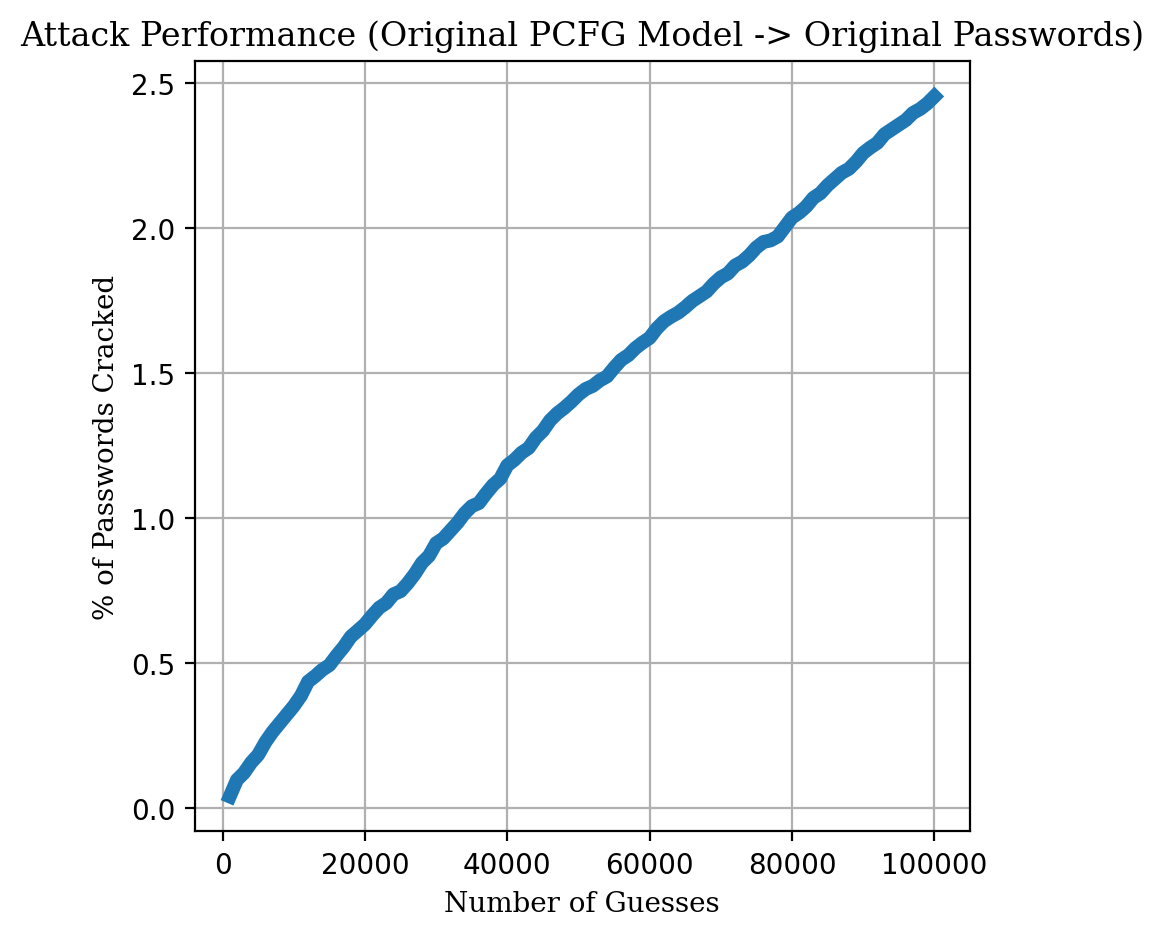

In [ ]:
graph_cracking_rate(crack_rate, "Attack Performance (Original PCFG Model -> Original Passwords)")